## 1. Setup and Data Loading

In [20]:
# Import libraries and define chart style

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, norm, mannwhitneyu
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

RED = '#D9534F'
BLUE = '#4682B4'
GREEN = '#2E8B57'
ORANGE = '#F0AD4E'
GRAY = '#888888'

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

In [21]:
# Load cleaned data and inspect target distribution

df = pd.read_csv('~/Desktop/Employee-Attrition- Portfolio/data/cleaned_employee_attrition.csv')

PAST_ATTRITION = 'attrition'
OVERALL_RATE = df[PAST_ATTRITION].mean()

print(f"Attrition rate: {OVERALL_RATE:.1%}")
print(df[PAST_ATTRITION].value_counts())

Attrition rate: 43.2%
attrition
0    676
1    515
Name: count, dtype: int64


## 2. Who Left?

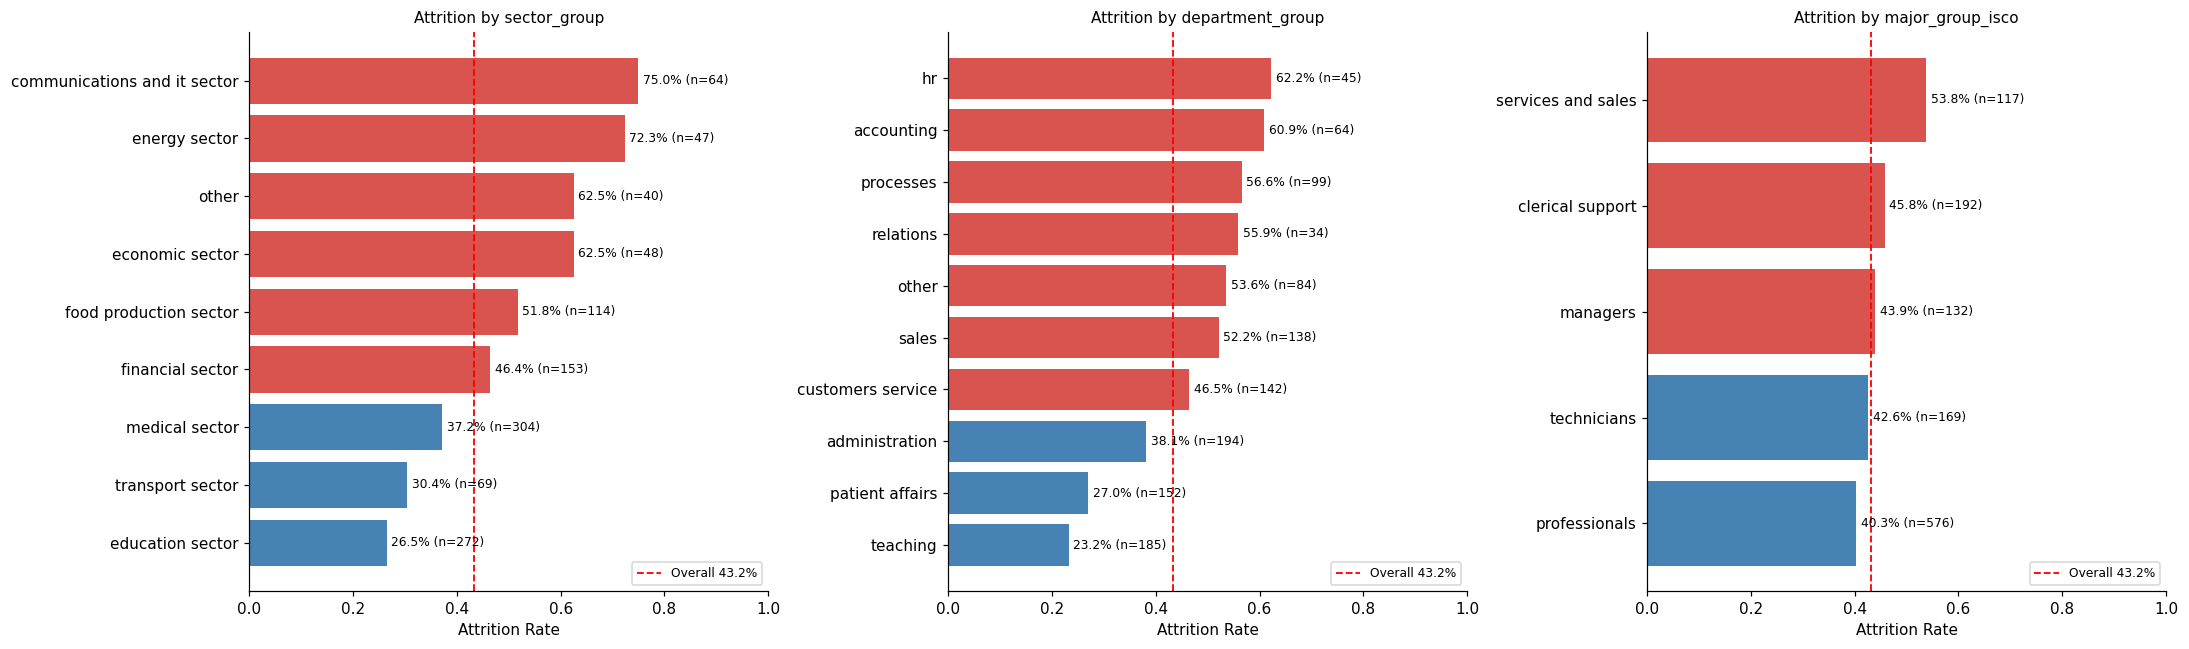

In [22]:
# Attrition rate by sector, department, major group

def attrition_by(df, col, min_n=30):
    g = df.groupby(col)[PAST_ATTRITION].agg(['count', 'mean'])
    g.columns = ['n', 'rate']
    return g[g['n'] >= min_n].sort_values('rate', ascending=True)

def plot_attrition_bars(ax, df, col, min_n=30, xlim_max=0.8):
    g = attrition_by(df, col, min_n)
    colors = [RED if r > OVERALL_RATE else BLUE for r in g['rate']]
    bars = ax.barh(g.index, g['rate'], color=colors)
    labels = [f'{r:.1%} (n={n})' for r, n in zip(g['rate'], g['n'])]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
    ax.axvline(OVERALL_RATE, color='red', ls='--', lw=1.2,
               label=f'Overall {OVERALL_RATE:.1%}')
    ax.set_xlim(0, 1)
    ax.set_title(f'Attrition by {col}', fontsize=10)
    ax.set_xlabel('Attrition Rate')
    ax.legend(loc='lower right', fontsize=8)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, col in zip(axes, ['sector_group', 'department_group', 'major_group_isco']):
    plot_attrition_bars(ax, df, col)
plt.tight_layout()
plt.show()

                      sector        major_group   n  rate  sector_avg  major_group_avg  gap_from_sector  gap_from_major_group   pulled_by
            education sector           managers  28 0.179       0.265            0.439           -0.086                -0.260      sector
            education sector      professionals 199 0.241       0.265            0.403           -0.024                -0.162      sector
              medical sector      professionals 173 0.312       0.372            0.403           -0.060                -0.091      sector
            education sector        technicians  39 0.385       0.265            0.426            0.120                -0.041 major group
            financial sector   clerical support  39 0.410       0.464            0.458           -0.054                -0.048 major group
              medical sector   clerical support  67 0.418       0.372            0.458            0.046                -0.040 major group
              medical sector      

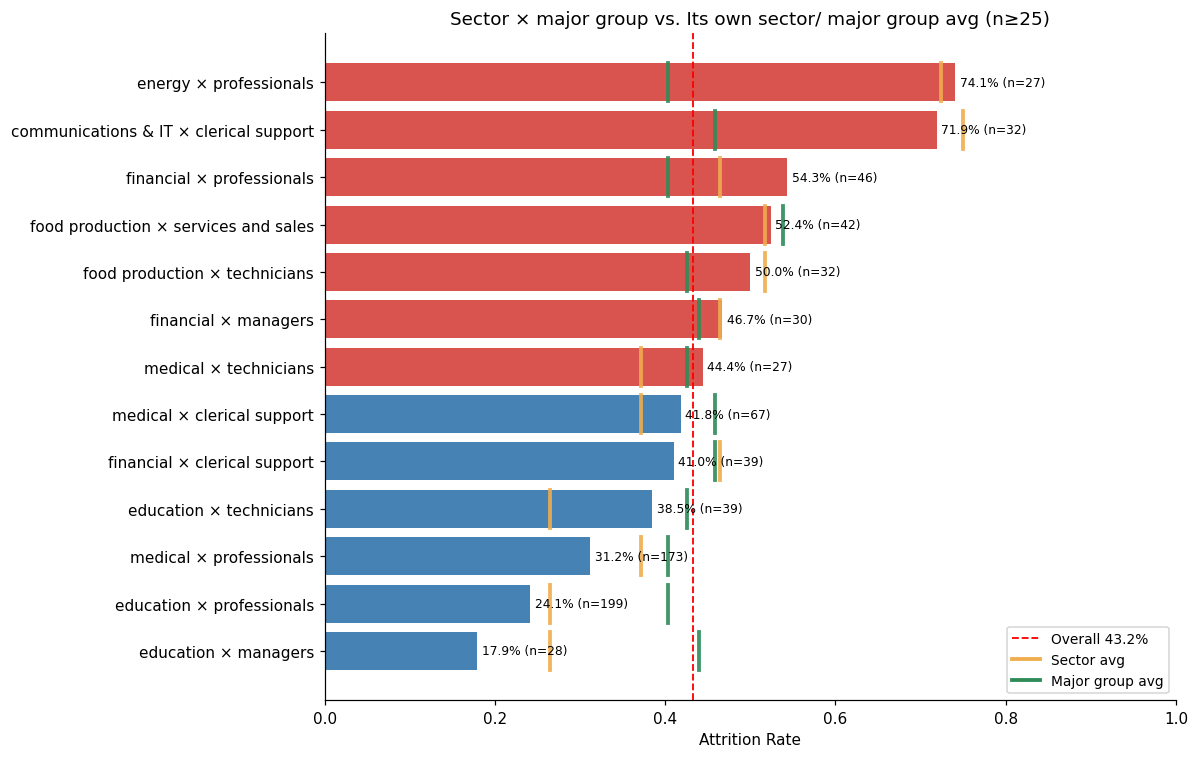

In [23]:
# Attrttion rate by Sector × Major Group

MIN_N = 25

ct = pd.crosstab(df['sector_group'], df['major_group_isco'])
valid_combos = ct.stack()[ct.stack() >= MIN_N].reset_index()
valid_combos.columns = ['sector', 'major_group', 'n']

combo_stats = []
for _, row in valid_combos.iterrows():
    sub = df[(df['sector_group'] == row['sector']) &
             (df['major_group_isco'] == row['major_group'])]
    rate = sub[PAST_ATTRITION].mean()
    combo_stats.append({
        'sector': row['sector'],
        'major_group': row['major_group'],
        'n': row['n'],
        'rate': round(rate, 3),
    })

combo_df = pd.DataFrame(combo_stats).sort_values('rate', ascending=True).reset_index(drop=True)

sector_avg = df.groupby('sector_group')[PAST_ATTRITION].mean()
major_group_avg = df.groupby('major_group_isco')[PAST_ATTRITION].mean()

decomp = combo_df.copy()
decomp['sector_avg'] = decomp['sector'].map(sector_avg).round(3)
decomp['major_group_avg'] = decomp['major_group'].map(major_group_avg).round(3)
decomp['gap_from_sector'] = (decomp['rate'] - decomp['sector_avg']).round(3)
decomp['gap_from_major_group'] = (decomp['rate'] - decomp['major_group_avg']).round(3)
decomp['pulled_by'] = decomp.apply(
    lambda r: 'sector' if abs(r['gap_from_sector']) < abs(r['gap_from_major_group'])
              else 'major group', axis=1)
print(decomp.to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 7))
labels = combo_df['sector'].str.replace(' sector', '').str.replace('communications and it', 'communications & IT') \
         + ' × ' + combo_df['major_group']
colors = [RED if r > OVERALL_RATE else BLUE for r in combo_df['rate']]
bars = ax.barh(labels, combo_df['rate'], color=colors)

bar_labels = [f'{r:.1%} (n={n})' for r, n in zip(combo_df['rate'], combo_df['n'])]
ax.bar_label(bars, labels=bar_labels, padding=3, fontsize=8)

for i, row in combo_df.iterrows():
    s_avg = sector_avg[row['sector']]
    j_avg = major_group_avg[row['major_group']]
    ax.plot([s_avg, s_avg], [i - 0.4, i + 0.4], color=ORANGE, lw=2.5, alpha=0.9)
    ax.plot([j_avg, j_avg], [i - 0.4, i + 0.4], color=GREEN, lw=2.5, alpha=0.9)

ax.axvline(OVERALL_RATE, color='red', ls='--', lw=1.2,
           label=f'Overall {OVERALL_RATE:.1%}')

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='red', ls='--', lw=1.2, label=f'Overall {OVERALL_RATE:.1%}'),
    Line2D([0], [0], color=ORANGE, lw=2.5, label='Sector avg'),
    Line2D([0], [0], color=GREEN, lw=2.5, label='Major group avg'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)

ax.set_xlim(0, 1)
ax.set_xlabel('Attrition Rate')
ax.set_title(f'Sector × major group vs. Its own sector/ major group avg (n≥{MIN_N})')
plt.tight_layout()
plt.show()

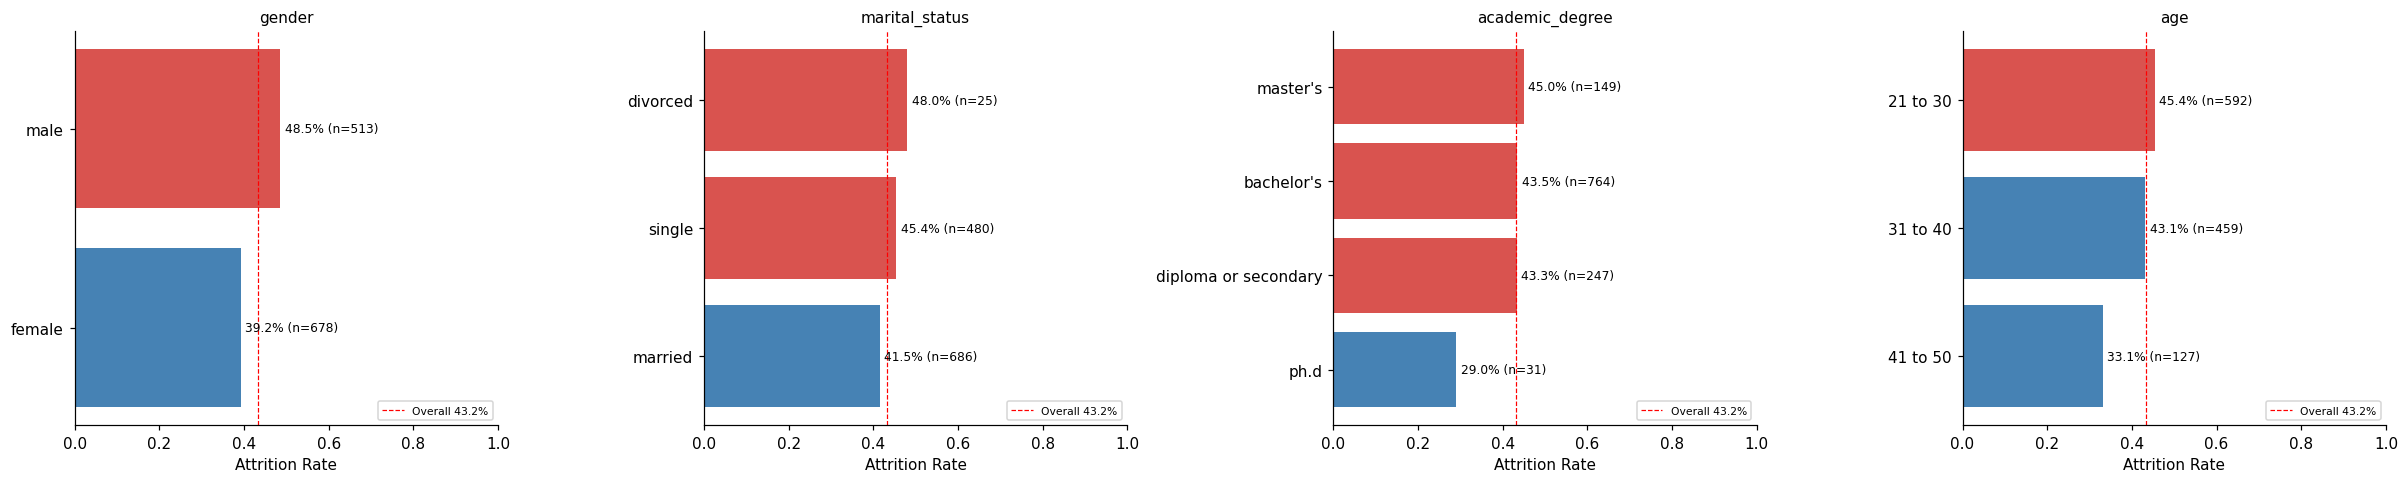

In [24]:
# Attrition rate by Demographics

df['marital_status_raw'] = df.apply(
    lambda r: 'married' if r['marital_married'] == 1
              else 'divorced' if r['marital_divorced'] == 1
              else 'single', axis=1)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
cols = ['gender_raw', 'marital_status_raw', 'academic_degree_raw', 'age_raw']

for ax, col in zip(axes, cols):
    g = attrition_by(df, col, min_n=25)
    colors = [RED if r > OVERALL_RATE else BLUE for r in g['rate']]

    bars = ax.barh(g.index, g['rate'], color=colors)
    labels = [f'{r:.1%} (n={n})' for r, n in zip(g['rate'], g['n'])]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)

    ax.axvline(OVERALL_RATE, color='red', ls='--', lw=0.8,
               label=f'Overall {OVERALL_RATE:.1%}')

    ax.set_xlim(0, 1)
    ax.set_title(col.replace('_raw', ''), fontsize=10)
    ax.set_xlabel('Attrition Rate')
    ax.legend(loc='lower right', fontsize=7)

plt.tight_layout() 
plt.show()

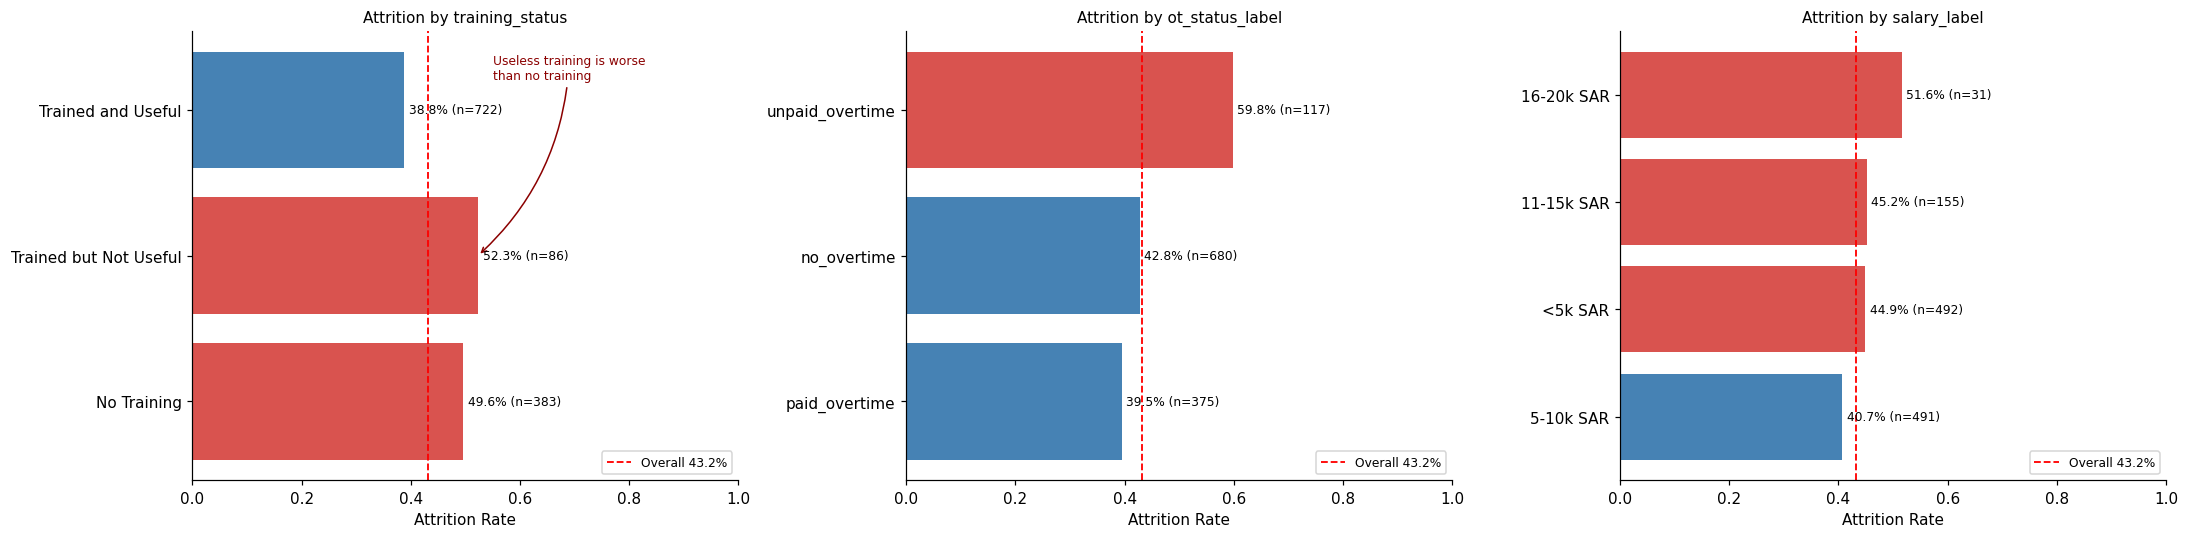

In [25]:
# Attrtion rate by Work Conditions
# Training status, overtime status, salary band

df['salary_label'] = df['monthly_salary'].map({
    1:'<5k SAR',2:'5-10k SAR',3:'11-15k SAR',4:'16-20k SAR',
    5:'21-25k SAR',6:'26-30k SAR',7:'31k+ SAR'})

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
cols = ['training_status', 'ot_status_label', 'salary_label']

for ax, col in zip(axes, cols):
    g = attrition_by(df, col, min_n=30)
    
    if col == 'training_status':
        order = ['No Training','Trained but Not Useful','Trained and Useful']
        g = g.reindex([x for x in order if x in g.index])
    
        y_pos = list(g.index).index('Trained but Not Useful')
        x_pos = g.loc['Trained but Not Useful', 'rate']
    
        ax.annotate('Useless training is worse\nthan no training',
                xy=(x_pos, y_pos),             
                xytext=(0.55, 0.95),         
                textcoords='axes fraction',
                fontsize=8, color='darkred',
                ha='left', va='top',
                arrowprops=dict(arrowstyle='->', color='darkred', lw=1,
                                connectionstyle='arc3,rad=-0.2'))
        
         
    colors = [RED if r > OVERALL_RATE else BLUE for r in g['rate']]
    bars = ax.barh(g.index, g['rate'], color=colors)
    
    labels = [f'{r:.1%} (n={n})' for r, n in zip(g['rate'], g['n'])]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
    
    ax.axvline(OVERALL_RATE, color='red', ls='--', lw=1.2,
               label=f'Overall {OVERALL_RATE:.1%}')
    
    ax.set_xlim(0, 1)
    ax.set_title(f'Attrition by {col}', fontsize=10)
    ax.set_xlabel('Attrition Rate')
    ax.legend(loc='lower right', fontsize=8)

plt.tight_layout(); plt.show()

**Observations:**
1. **The highest gap of Attrtion rate is by sector**, from 27% (Education, n=272) to 75% (Communications & IT, n=64), a 48% gap.
2. Sector dominates in all Sector  but four combines (Education × Technicians, Financial × Clerical, Medical × Clerical, Medical × Technicians).
3. **There are no meaningful variation by demographics**. PhD shows lower attrition but it is not interpretable for n=31.
4. Salary band shows no huge gap but there are differences in the overtime status:
unpaid overtime (59.8%, n=117) > No overtime (42.8%, n=680) > Paid overtime (39.5%, n=375). **And useless training** (52.3%, n=86) **is slightly worse than notraining** (49.6%, n=383).

## 3. What Correlates？

FDR-corrected Spearman correlations. 
Variables with |r| ≥ 0.10 and p_fdr < 0.05 are kept. 

Qualifying variables: 18
                  variable      r  p_fdr
         job_opportunities  0.349  0.000
        years_last_org_mid -0.273  0.000
             job_stability -0.254  0.000
        deserved_promotion -0.239  0.000
      emotional_commitment -0.231  0.000
rewards_wages_satisfaction -0.228  0.000
          job_satisfaction -0.221  0.000
               job_support -0.182  0.000
               recognition -0.170  0.000
            job_engagement -0.158  0.000
         work_life_balance -0.157  0.000
  psychological_exhaustion  0.154  0.000
           useful_training -0.146  0.000
      years_experience_mid  0.137  0.000
  environment_satisfaction -0.130  0.000
           unpaid_overtime  0.111  0.000
       training_status_ord -0.107  0.000
           physical_stress  0.101  0.001


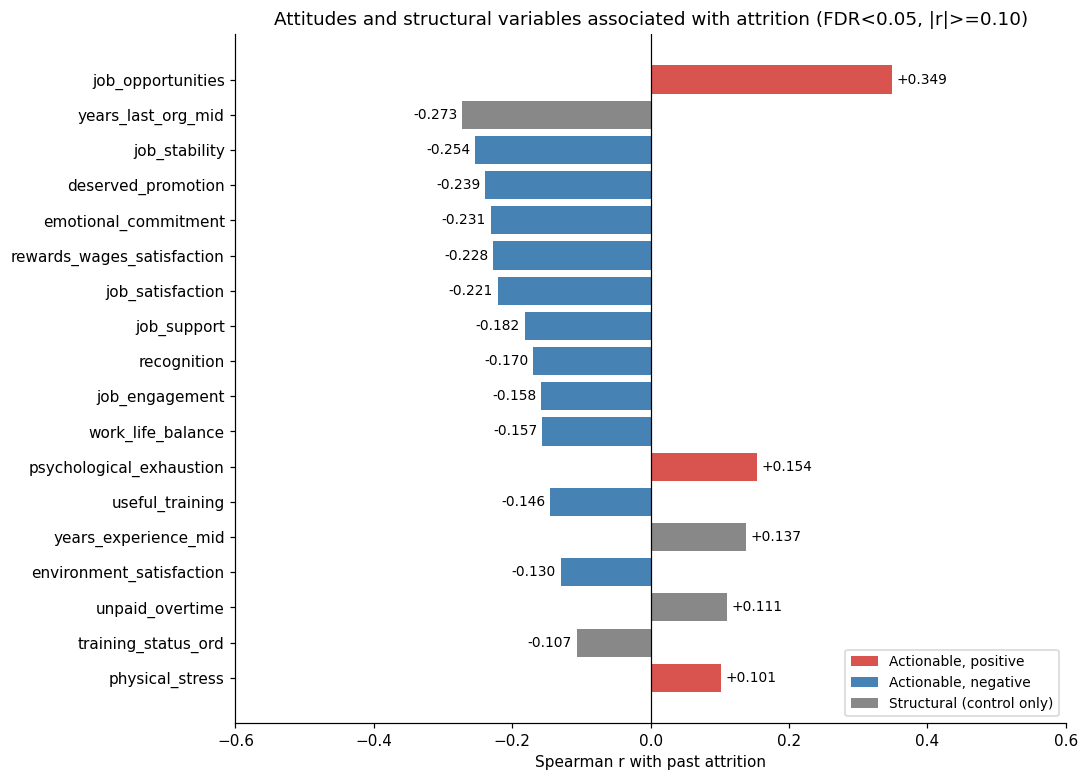

In [26]:
# Correlation

EXCLUDE = ['id', PAST_ATTRITION] \
          + [c for c in df.columns if c.endswith('_raw')] \
          + [c for c in df.columns if c.endswith('_missing')] \
          + ['isco_2digit', 'isco_major', 'ot_status_label', 'training_status']
REDUNDANT = ['years_last_org', 'years_experience', 'age', 'monthly_salary',
             'ot_3', 'training_programs']

ACTIONABLE = ['job_opportunities', 'deserved_promotion',
              'rewards_wages_satisfaction', 'job_satisfaction',
              'emotional_commitment', 'job_stability',
              'job_engagement', 'work_life_balance',
              'psychological_exhaustion', 'recognition',
              'job_support', 'environment_satisfaction',
              'useful_training', 'physical_stress', 'health_issues']

STRUCTURAL = ['age_mid', 'gender', 'marital_married', 'marital_divorced',
              'academic_degree', 'distance_to_work',
              'years_experience_mid', 'years_last_org_mid',
              'monthly_salary_mid']

numeric_cols = [c for c in df.select_dtypes(include='number').columns
                if c not in EXCLUDE and c not in REDUNDANT]

results = []
for col in numeric_cols:
    if df[col].nunique() < 2:
        continue
    r, p = spearmanr(df[col], df[PAST_ATTRITION])
    results.append({'variable': col, 'r': r, 'p': p, 'abs_r': abs(r)})

corr_df = pd.DataFrame(results)
corr_df['p_fdr'] = multipletests(corr_df['p'], method='fdr_bh')[1]
corr_df = corr_df[(corr_df['p_fdr'] < 0.05) & (corr_df['abs_r'] >= 0.10)]
corr_df = corr_df.sort_values('abs_r', ascending=False).reset_index(drop=True)

print(f"Qualifying variables: {len(corr_df)}")
print(corr_df[['variable', 'r', 'p_fdr']].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, max(6, len(corr_df) * 0.4)))
plot_data = corr_df.sort_values('abs_r', ascending=True).reset_index(drop=True)

def bar_color(row):
    if row['variable'] in ACTIONABLE:
        return RED if row['r'] > 0 else BLUE
    return '#888888'  # structural, any sign

colors = [bar_color(row) for _, row in plot_data.iterrows()]
bars = ax.barh(plot_data['variable'], plot_data['r'], color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.bar_label(bars, labels=[f'{r:+.3f}' for r in plot_data['r']],
             padding=3, fontsize=9)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=RED, label='Actionable, positive'),
    Patch(facecolor=BLUE, label='Actionable, negative'),
    Patch(facecolor='#888888', label='Structural (control only)'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)

ax.set_xlabel('Spearman r with past attrition')
ax.set_title('Attitudes and structural variables associated with attrition (FDR<0.05, |r|>=0.10)')
ax.set_xlim(-0.6, 0.6)
plt.tight_layout(); plt.show()

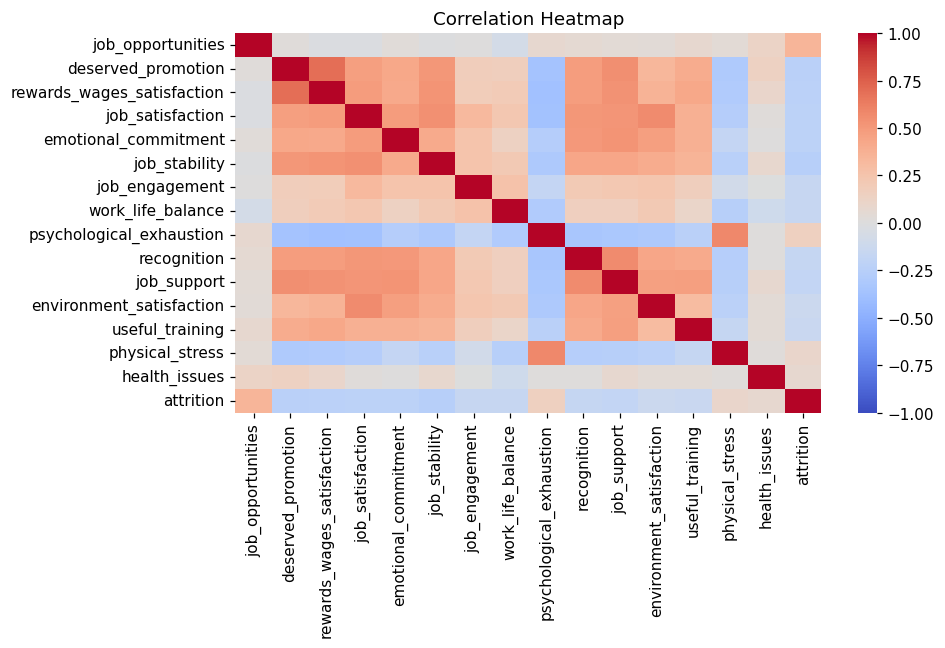

In [27]:
# Correlation heatmap

plt.figure(figsize=(9, 6))
corr_cols = ACTIONABLE + ['attrition']
corr = df[corr_cols].corr()
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, annot=False)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

**Observations:**
1. 18 variables pass FDR < 0.05 and |r| ≥ 0.10. The strongest positive correlate is job_opportunities (r = 0.349). The strongest negative correlates are years_last_org_mid (r = -0.273) and job_stability (r = -0.254).
2. Attrition is more strongly associated with attitudinal and experiential factors than with demographic structure.


 ## 4. Do drivers Vary Across Groups?

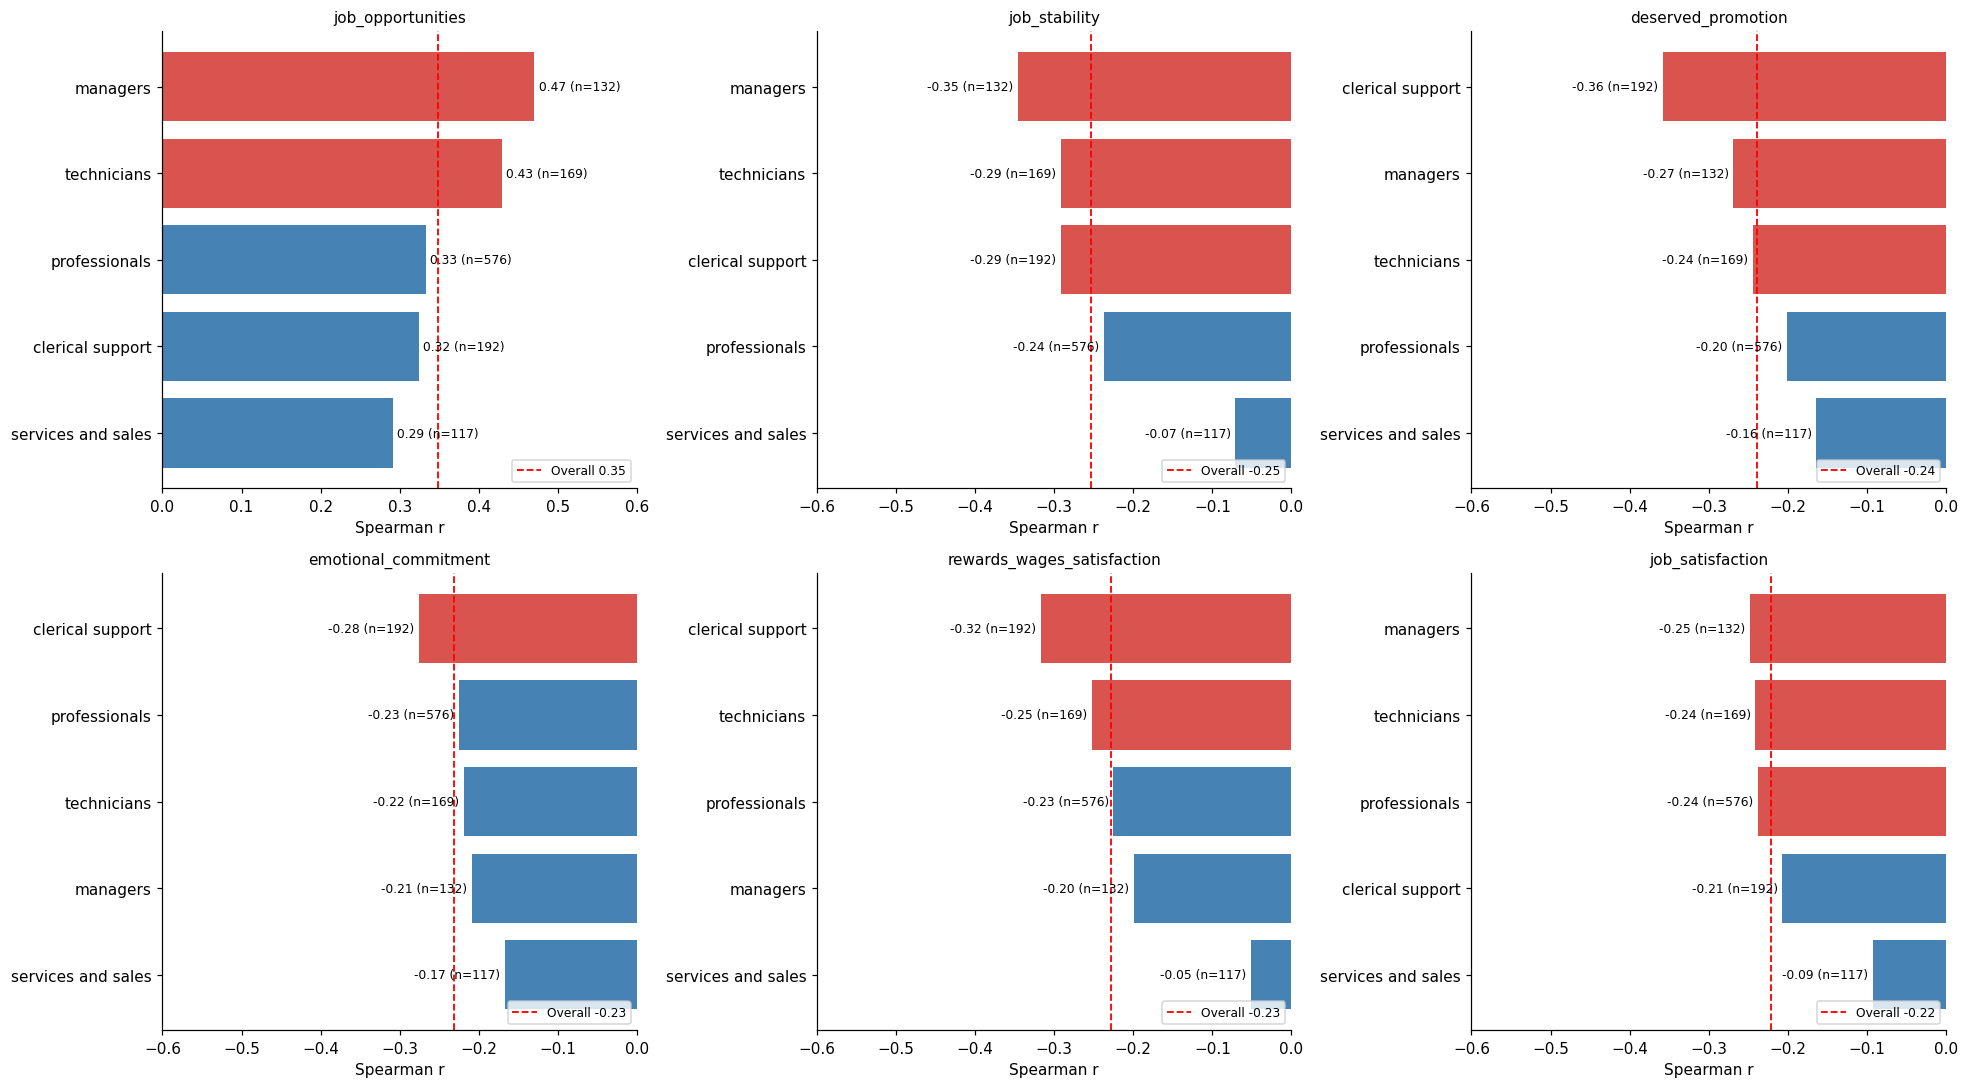

In [28]:
# Core drivers stratified by ISCO major group

CORE = ['job_opportunities', 'job_stability', 'deserved_promotion',
        'emotional_commitment', 'rewards_wages_satisfaction', 'job_satisfaction']

def stratify(df, driver, strat_col='major_group_isco', min_n=60):
    overall_r, _ = spearmanr(df[driver], df[PAST_ATTRITION])
    rows = []
    for layer, sub in df.groupby(strat_col):
        if len(sub) < min_n:
            continue
        r, p = spearmanr(sub[driver], sub[PAST_ATTRITION])
        rows.append({
            'driver': driver, 'stratum': layer, 'n': len(sub),
            'overall_r': round(overall_r, 3),
            'layer_r': round(r, 3),
            'layer_abs_r': round(abs(r), 3),
            'delta': round(r - overall_r, 3),
            'p': p
        })
    return pd.DataFrame(rows)

core_results = pd.concat([stratify(df, d) for d in CORE], ignore_index=True)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, driver in zip(axes.flat, CORE):
    sub = core_results[core_results['driver'] == driver].sort_values('layer_abs_r', ascending=True)
    overall_r = sub['overall_r'].iloc[0]

    colors = []
    for r in sub['layer_r']:
        if (r > 0) != (overall_r > 0):
            colors.append(ORANGE)  # opposite direction
        elif abs(r) > abs(overall_r):
            colors.append(RED)  # stronger than overall
        else:
            colors.append(BLUE)  # weaker than overall

    bars = ax.barh(sub['stratum'], sub['layer_r'], color=colors)
    ax.axvline(overall_r, color='red', ls='--', lw=1.2,
               label=f'Overall {overall_r:.2f}')
    ax.axvline(0, color='gray', lw=0.5)
    labels = [f'{r:.2f} (n={n})' for r, n in zip(sub['layer_r'], sub['n'])]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)

    if overall_r > 0:
        ax.set_xlim(0, 0.6)
    else:
        ax.set_xlim(-0.6, 0)

    ax.set_title(driver, fontsize=10)
    ax.set_xlabel('Spearman r')
    ax.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()


 professionals (n=576) 
                  variable      r  abs_r
         job_opportunities  0.333  0.333
          job_satisfaction -0.238  0.238
             job_stability -0.237  0.237
rewards_wages_satisfaction -0.225  0.225
      emotional_commitment -0.225  0.225

 technicians (n=169) 
                  variable      r  abs_r
         job_opportunities  0.429  0.429
            job_engagement -0.307  0.307
             job_stability -0.292  0.292
rewards_wages_satisfaction -0.252  0.252
               recognition -0.244  0.244

 managers (n=132) 
                variable      r  abs_r
       job_opportunities  0.470  0.470
       work_life_balance -0.366  0.366
           job_stability -0.346  0.346
psychological_exhaustion  0.288  0.288
      deserved_promotion -0.269  0.269

 clerical support (n=192) 
                  variable      r  abs_r
        deserved_promotion -0.358  0.358
         job_opportunities  0.324  0.324
rewards_wages_satisfaction -0.317  0.317
             j

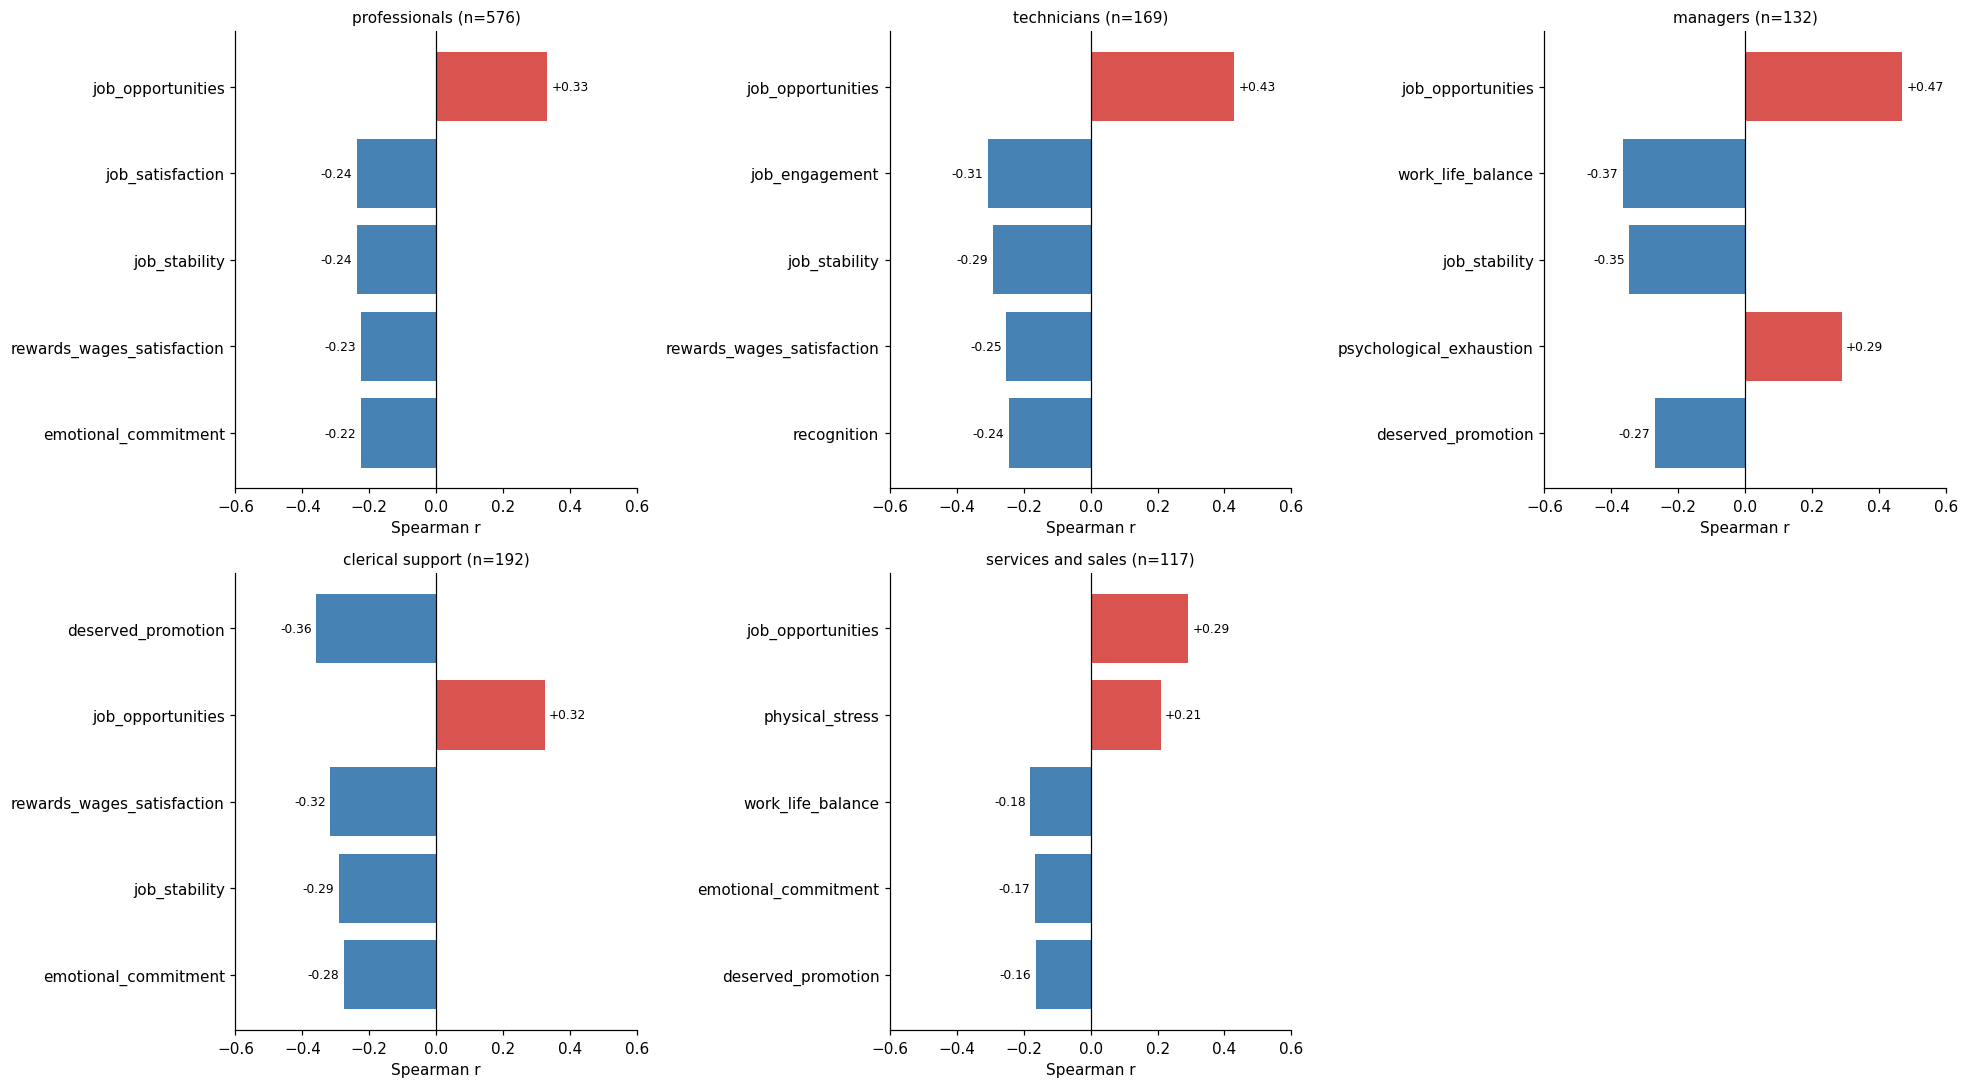

In [29]:
# Top5 drivers per ISCO Major Group

ACTIONABLE = ['job_opportunities', 'job_stability', 'deserved_promotion',
              'emotional_commitment', 'rewards_wages_satisfaction',
              'job_satisfaction', 'job_support', 'recognition',
              'job_engagement', 'work_life_balance',
              'psychological_exhaustion', 'useful_training',
              'environment_satisfaction', 'training_status_ord',
              'unpaid_overtime', 'physical_stress']

subgroup_tops = {}
for subgroup in df['major_group_isco'].unique():
    sub = df[df['major_group_isco'] == subgroup]
    if len(sub) < 60:
        continue
    results = []
    for col in ACTIONABLE:
        if col not in sub.columns or sub[col].nunique() < 2:
            continue
        r, p = spearmanr(sub[col], sub[PAST_ATTRITION])
        results.append({'variable': col, 'r': r, 'abs_r': abs(r)})
    top = pd.DataFrame(results).sort_values('abs_r', ascending=False).head(5)
    subgroup_tops[subgroup] = top
    print(f"\n {subgroup} (n={len(sub)}) ")
    print(top[['variable', 'r', 'abs_r']].round(3).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes_flat = axes.flatten()

for ax, (subgroup, top) in zip(axes_flat, subgroup_tops.items()):
    plot_data = top.sort_values('abs_r', ascending=True)  # strongest at top
    colors = [RED if r > 0 else BLUE for r in plot_data['r']]
    bars = ax.barh(plot_data['variable'], plot_data['r'], color=colors)
    ax.axvline(0, color='black', lw=0.8)
    ax.bar_label(bars, labels=[f'{r:+.2f}' for r in plot_data['r']],
                 padding=3, fontsize=8)
    ax.set_xlabel('Spearman r')
    ax.set_title(f'{subgroup} (n={len(df[df["major_group_isco"]==subgroup])})',
                 fontsize=10)
    ax.set_xlim(-0.6, 0.6)

for ax in axes_flat[len(subgroup_tops):]:
    ax.set_visible(False)

plt.tight_layout(); plt.show()

**Observations:**
1. **Job_opportunities is a universal correlate**, but its strength varies by major group: managers 0.470, technicians 0.429, professionals 0.333, clerical 0.324.
2. **Services and sales is not sensitive to most** of the six core variables. Apart from job_opportunities, its second strongest correlate is physical_stress (0.21), which does not appear as a top correlate for other major groups.
3. **Clerical support is the only** group where **the top correlate** is not job_opportunities but **deserved_promotion (-0.36).**

## 5. When Does Each Driver Matter Most?

In [30]:
# Buffer exploratory
# FDR<0.05, |delta| >= 0.50


SUBGROUP_DRIVERS = {
    'clerical support': ['deserved_promotion', 'rewards_wages_satisfaction',
                         'job_stability', 'emotional_commitment'],
    'managers': ['job_opportunities', 'work_life_balance',
                 'job_stability', 'psychological_exhaustion'],
    'professionals': ['job_opportunities', 'job_satisfaction',
                      'job_stability', 'rewards_wages_satisfaction'],
    'technicians': ['job_opportunities', 'job_engagement',
                    'job_stability', 'recognition'],
}


def buffer_scan(df, subgroup_col, subgroup_values, subgroup_drivers,
                buffer_pool, min_n=30):
    rows = []
    for subgroup in subgroup_values:
        if subgroup_col == 'major_group_isco':
            sub = df[df['major_group_isco'] == subgroup].copy()
            drivers = subgroup_drivers.get(subgroup, [])
        else:
            sector, major_group = subgroup
            sub = df[(df['sector_group'] == sector) &
                     (df['major_group_isco'] == major_group)].copy()
            drivers = subgroup_drivers.get(major_group, [])
        if len(sub) < 2 * min_n:
            continue
        for driver in drivers:
            if driver not in sub.columns:
                continue
            driver_r = spearmanr(sub[driver], sub[PAST_ATTRITION])[0]
            for buf in buffer_pool:
                if buf == driver or buf not in sub.columns:
                    continue
                if sub[buf].nunique() < 2:
                    continue
                if sub[buf].nunique() == 2:
                    vals = sorted(sub[buf].unique())
                    high = sub[sub[buf] == vals[1]]
                    low = sub[sub[buf] == vals[0]]
                else:
                    med = sub[buf].median()
                    high = sub[sub[buf] > med]
                    low = sub[sub[buf] <= med]
                if len(high) < min_n or len(low) < min_n:
                    continue
                r_high = spearmanr(high[driver], high[PAST_ATTRITION])[0]
                r_low = spearmanr(low[driver], low[PAST_ATTRITION])[0]
                z1, z2 = np.arctanh(np.clip([r_high, r_low], -0.99, 0.99))
                se = np.sqrt(1 / (len(high) - 3) + 1 / (len(low) - 3))
                p_diff = 2 * (1 - norm.cdf(abs((z1 - z2) / se)))
                rows.append({
                    'subgroup': subgroup if subgroup_col == 'major_group_isco'
                                else f"{sector} × {major_group}",
                    'driver': driver, 'buffer': buf,
                    'n_high': len(high), 'n_low': len(low),
                    'r_high': round(r_high, 3), 'r_low': round(r_low, 3),
                    'delta': round(r_high - r_low, 3),
                    'p_diff': p_diff, '_driver_r': driver_r
                })
    result = pd.DataFrame(rows)
    if result.empty:
        return result
    result['p_fdr'] = np.nan
    for sg in result['subgroup'].unique():
        mask = result['subgroup'] == sg
        result.loc[mask, 'p_fdr'] = multipletests(
            result.loc[mask, 'p_diff'], method='fdr_bh')[1]

    def classify(row):
        if row['p_fdr'] >= 0.05 or abs(row['delta']) < 0.15:
            return 'ns'
        if row['_driver_r'] > 0:
            return 'buffer' if row['delta'] < 0 else 'amplify'
        return 'buffer' if row['delta'] > 0 else 'intensify'
    result['pattern'] = result.apply(classify, axis=1)
    return result.drop(columns='_driver_r')

major_group_scan = buffer_scan(
    df, 'major_group_isco',
    ['clerical support', 'managers', 'professionals', 'technicians'],
    SUBGROUP_DRIVERS, ACTIONABLE
)

ct = pd.crosstab(df['sector_group'], df['major_group_isco'])
large_combos = ct.stack()[ct.stack() >= 60].index.tolist()
combo_scan = buffer_scan(
    df, 'combo', large_combos, SUBGROUP_DRIVERS, ACTIONABLE
)

sig_major_group = major_group_scan[
    (major_group_scan['p_fdr'] < 0.05) & (abs(major_group_scan['delta']) >= 0.50)
].sort_values('delta', key=abs, ascending=False).reset_index(drop=True)

sig_combo = combo_scan[
    (combo_scan['p_fdr'] < 0.05) & (abs(combo_scan['delta']) >= 0.50)
].sort_values('delta', key=abs, ascending=False).reset_index(drop=True)

print(f"Major-group interactions: {len(sig_major_group)}")
display(sig_major_group[['subgroup', 'driver', 'buffer',
                'n_high', 'n_low', 'r_high', 'r_low',
                'delta', 'p_fdr', 'pattern']].round(3))

print(f"\nSector × Major-group interactions: {len(sig_combo)}")
display(sig_combo[['subgroup', 'driver', 'buffer',
                   'n_high', 'n_low', 'r_high', 'r_low',
                   'delta', 'p_fdr', 'pattern']].round(3))

/var/folders/22/c21lr3610pl1ctsrtt3zh3rh0000gn/T/ipykernel_94079/2291796319.py:50: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_high = spearmanr(high[driver], high[PAST_ATTRITION])[0]


Major-group interactions: 4


,subgroup,driver,buffer,n_high,n_low,r_high,r_low,delta,p_fdr,pattern
0,clerical support,deserved_promotion,rewards_wages_satisfaction,76,116,-0.483,0.159,-0.642,0.000,intensify
1,clerical support,rewards_wages_satisfaction,deserved_promotion,61,131,-0.535,0.043,-0.578,0.001,intensify
2,managers,job_stability,job_opportunities,77,55,-0.144,-0.691,0.546,0.004,buffer
3,clerical support,rewards_wages_satisfaction,recognition,111,81,-0.435,0.109,-0.544,0.002,intensify



Sector × Major-group interactions: 6


,subgroup,driver,buffer,n_high,n_low,r_high,r_low,delta,p_fdr,pattern
0,medical sector × professionals,job_stability,psychological_exhaustion,53,120,0.165,-0.561,0.726,0.000,buffer
1,medical sector × clerical support,rewards_wages_satisfaction,recognition,34,33,-0.485,0.115,-0.600,0.028,intensify
2,medical sector × clerical support,deserved_promotion,useful_training,32,35,-0.645,-0.047,-0.599,0.028,intensify
3,medical sector × clerical support,deserved_promotion,recognition,34,33,-0.583,0.008,-0.591,0.028,intensify
4,medical sector × clerical support,rewards_wages_satisfaction,useful_training,32,35,-0.542,0.039,-0.581,0.028,intensify
5,medical sector × clerical support,deserved_promotion,training_status_ord,31,36,-0.688,-0.136,-0.552,0.028,intensify


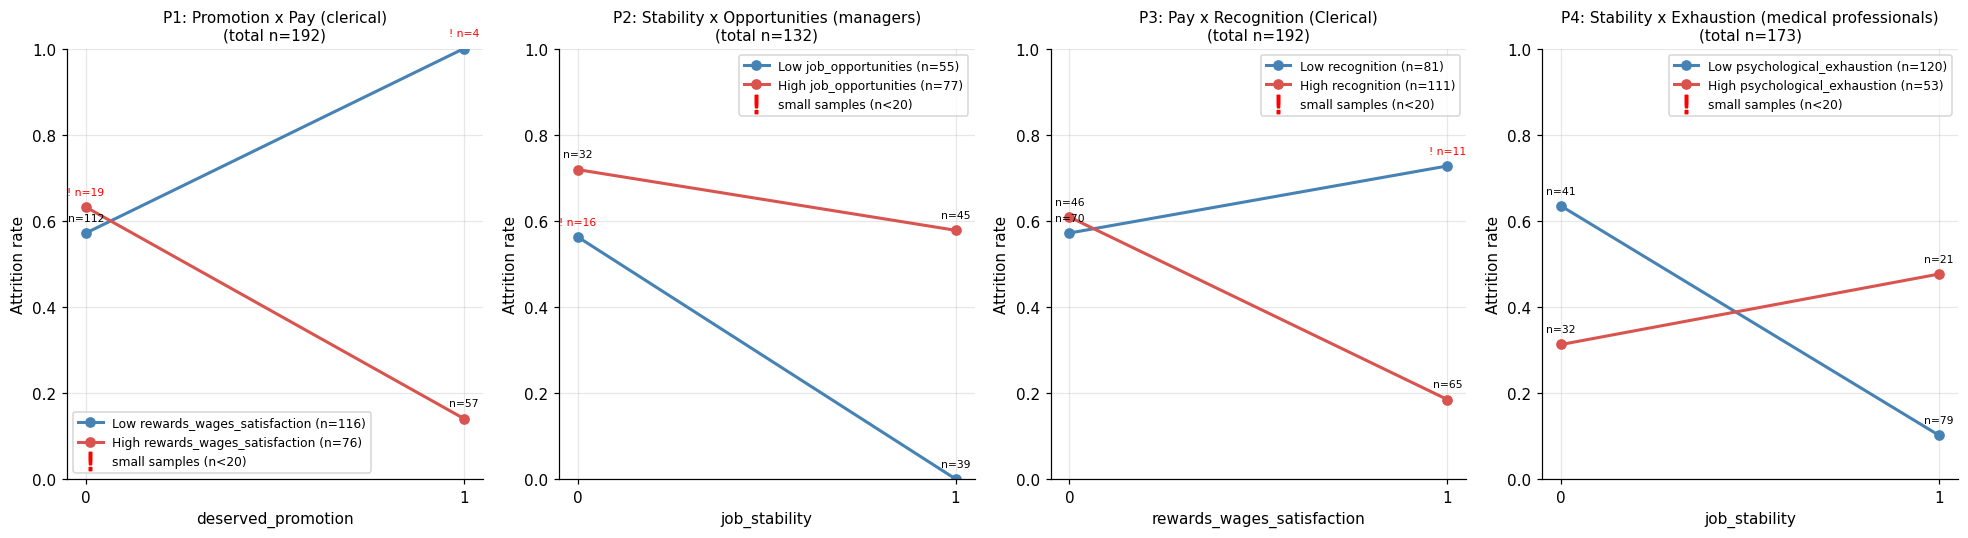

In [31]:
# simple slop
def split_buf(sub, buf):
    if sub[buf].nunique()==2:
        vals = sorted(sub[buf].unique())
        return sub[sub[buf]==vals[0]], sub[sub[buf]==vals[1]]
    med = sub[buf].median()
    return sub[sub[buf]<=med], sub[sub[buf]>med]

def plot_simple_slopes(sub, driver, buffer, title, ax):
    low, high = split_buf(sub, buffer)
    vals = sorted(sub[driver].unique())
    for label, part, color in [('Low '+buffer, low, BLUE), ('High '+buffer, high, RED)]:
        ns = [len(part[part[driver]==v]) for v in vals]
        rates = [part[part[driver]==v][PAST_ATTRITION].mean() for v in vals]
        ax.plot(vals, rates, marker='o', lw=2, color=color, label=f'{label} (n={len(part)})')
        for x, y, n in zip(vals, rates, ns):
            if n < 20:
                ax.annotate(f'! n={n}', (x, y), textcoords='offset points',
                            xytext=(0, 8), ha='center', fontsize=7, color='red')
            else:
                ax.annotate(f'n={n}', (x, y), textcoords='offset points',
                            xytext=(0, 8), ha='center', fontsize=7, color='black')

    ax.set_xlabel(driver); ax.set_ylabel('Attrition rate'); ax.set_ylim(0,1)
    ax.set_xticks(vals); ax.set_title(f'{title}\n(total n={len(sub)})', fontsize=10)

    handles, labels = ax.get_legend_handles_labels()
    dummy, = ax.plot([], [], linestyle='none', marker='$!$', color='red', markersize=12)
    handles.append(dummy)
    labels.append('small samples (n<20)')
    ax.legend(handles, labels, fontsize=8)
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# P1 clerical support: Promotion x Pay
sub = df[df['major_group_isco']=='clerical support']
plot_simple_slopes(sub, 'deserved_promotion','rewards_wages_satisfaction',
                   'P1: Promotion x Pay (clerical)', axes[0])

# P2: Managers: stability x  opportunities
sub = df[df['major_group_isco']=='managers']
plot_simple_slopes(sub, 'job_stability','job_opportunities',
                   'P2: Stability x Opportunities (managers)', axes[1])
# P3: Clerical support: Pay x Recognition
sub = df[df['major_group_isco']=='clerical support']
plot_simple_slopes(sub, 'rewards_wages_satisfaction','recognition',
                   'P3: Pay x Recognition (Clerical)', axes[2])

# P3: Medical professionals: stability x exhaustion
sub = df[(df['sector_group']=='medical sector') & (df['major_group_isco']=='professionals')]
plot_simple_slopes(sub, 'job_stability','psychological_exhaustion',
                   'P4: Stability x Exhaustion (medical professionals)', axes[3])

plt.tight_layout()
plt.show()

In [32]:
# Check if patterns are driven by one sector
clerical_sector = (
    df[df['major_group_isco'] == 'clerical support']
    .groupby('sector_group')
    .agg(n=(PAST_ATTRITION, 'size'),
         attrition_rate=(PAST_ATTRITION, 'mean'))
    .sort_values('n', ascending=False)
    .round(3)
)
print('Clerical support across sectors')
display(clerical_sector)

# Sector distribution of managers
managers_sector = (
    df[df['major_group_isco'] == 'managers']
    .groupby('sector_group')
    .agg(n=(PAST_ATTRITION, 'size'),
         attrition_rate=(PAST_ATTRITION, 'mean'))
    .sort_values('n', ascending=False)
    .round(3)
)
print('Managers across sectors')
display(managers_sector)

Clerical support across sectors


,n,attrition_rate
sector_group,,
medical sector,67,0.418
financial sector,39,0.410
communications and it sector,32,0.719
transport sector,17,0.294
food production sector,7,0.286
energy sector,6,0.500
economic sector,5,0.800
other,5,0.200
tourism sector,5,0.200


Managers across sectors


,n,attrition_rate
sector_group,,
financial sector,30,0.467
education sector,28,0.179
medical sector,23,0.522
economic sector,11,0.545
transport sector,10,0.200
food production sector,8,0.375
other,6,0.833
communications and it sector,4,0.750
tourism sector,4,0.750


In [33]:
# Cross- sector analysis in exhaustion x stability 
MIN_N = 30
rows = []
for sector, sub in df.groupby('sector_group'):
    if len(sub) < 2*MIN_N: continue
    med = sub['psychological_exhaustion'].median()
    high = sub[sub['psychological_exhaustion']>med]
    low = sub[sub['psychological_exhaustion']<=med]
    if len(high)<MIN_N or len(low)<MIN_N: continue
    r_h = spearmanr(high['job_stability'], high[PAST_ATTRITION])[0]
    r_l = spearmanr(low['job_stability'], low[PAST_ATTRITION])[0]
    rows.append({'sector':sector,'n':len(sub),'r_exhausted':r_h,'r_not_exhausted':r_l,'delta':r_h-r_l})
rob = pd.DataFrame(rows).sort_values('delta', ascending=False)
print(rob.round(3).to_string(index=False))

                sector   n  r_exhausted  r_not_exhausted  delta
        medical sector 304        0.164           -0.519  0.683
food production sector 114       -0.129           -0.368  0.239
      education sector 272       -0.113           -0.327  0.214
      financial sector 153       -0.158           -0.274  0.116


**Observations:**
1. When psychological_exhaustion is high, higher job_stability is associated with higher attrition (from 0.3 to 0.48). 


**The direction (Small sample results) of the further qualitative interviews for HRs**
1. For clerical support, the strongest exit combination is low rewards_wages_satisfaction × low deserved_promotion. When either RWS or DP is high alone, attrition is still higher than when both are low.
2. When external job opportunities are high (red line), the negative association between job_stability and attrition is markedly weaker (flatter slope; attrition drops only from 0.72 to 0.58). When external opportunities are low (blue line), higher job_stability is associated with a steep drop in attrition (from 0.56 to 0.0).
3. When recognition is low, higher rewards_wages_satisfaction is associated with higher attrition (from 0.56 to 0.72).
                                                          

**What we found:**
1. The same sector can have very different turnover across job major groups like clerical vs. managerial roles.
2. Main-effect correlates (job opportunities, stability, promotion, pay satisfaction) mask important subgroup differences: the same factor can protect one group and intensify another.

**What this means for HR:**

A one-size-fits-all retention playbook will misallocate resources. 
    
**What's next:**

The modeling tests whether these effects hold after adjusting for confounders (logistic regression, CART), and evaluates predictive performance on a test set.